# LSTM exploration

In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

sys.path.append('../')

from model_recurrent import Model

In [2]:
df = pd.read_csv("../full_data.csv")

# Global models

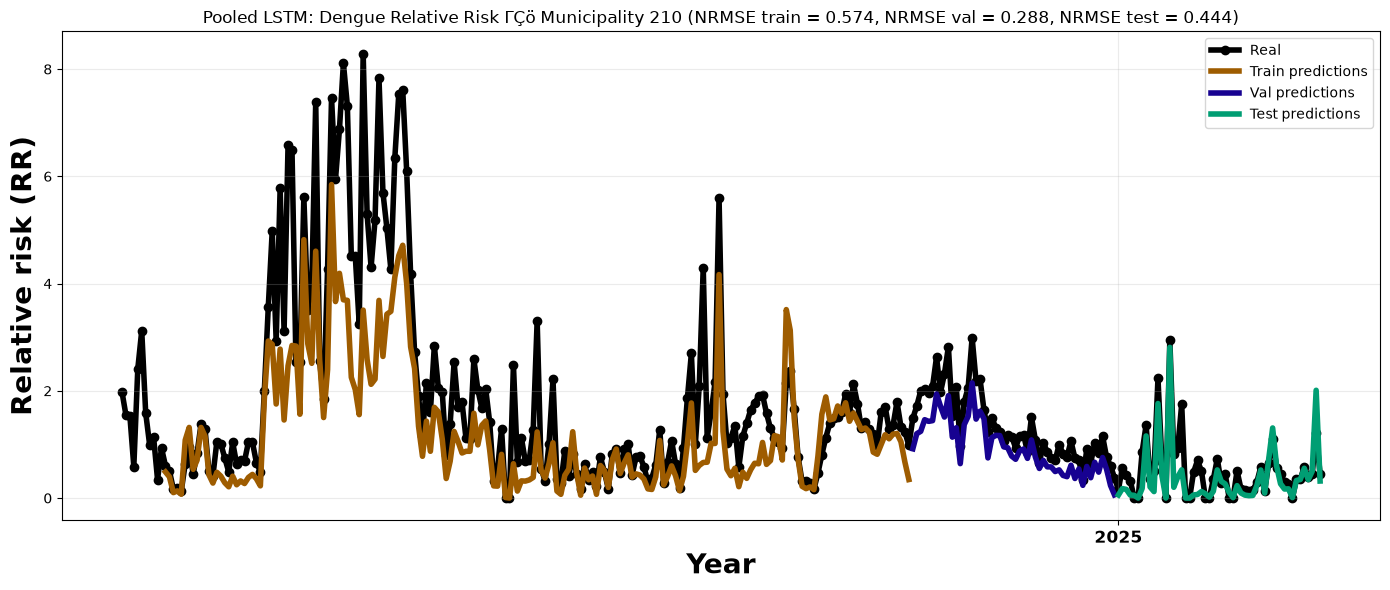

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 210 (NRMSE train = 0.574, NRMSE val = 0.288, NRMSE test = 0.444)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [3]:
model0 = Model(df, "210")
model0.plot_forecast_lstm_full()

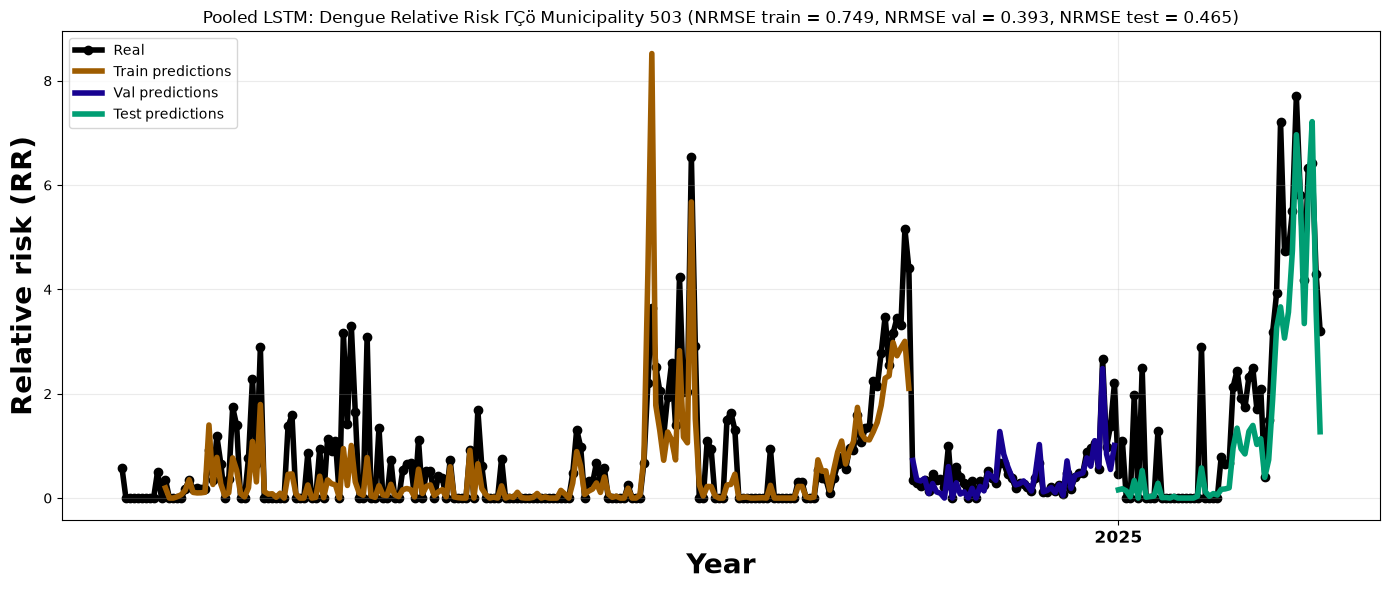

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 503 (NRMSE train = 0.749, NRMSE val = 0.393, NRMSE test = 0.465)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [4]:
model0 = Model(df, "503")
model0.plot_forecast_lstm_full()

# Individual models

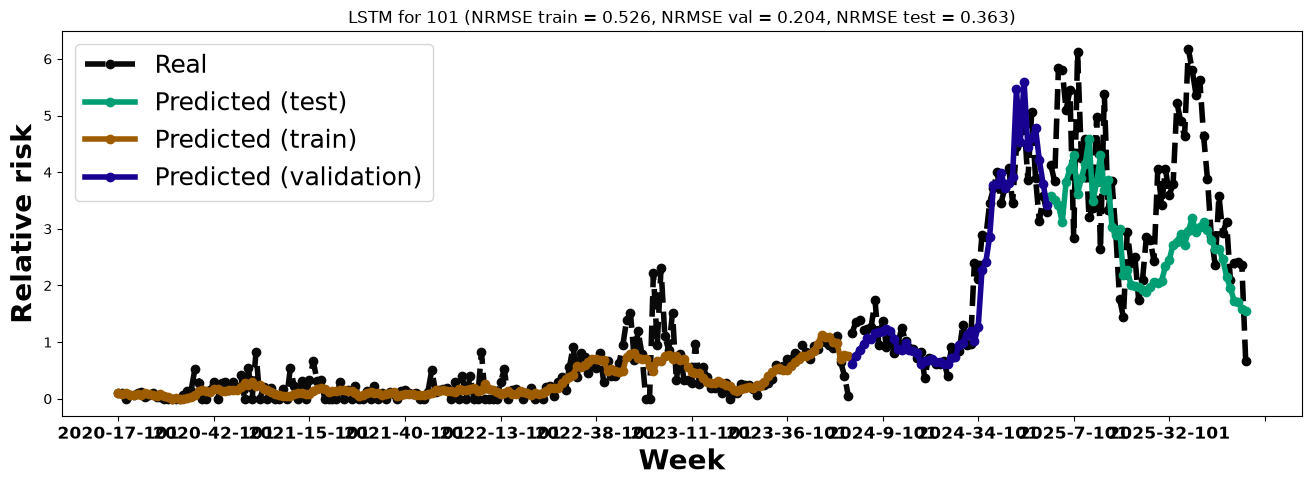

In [5]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()

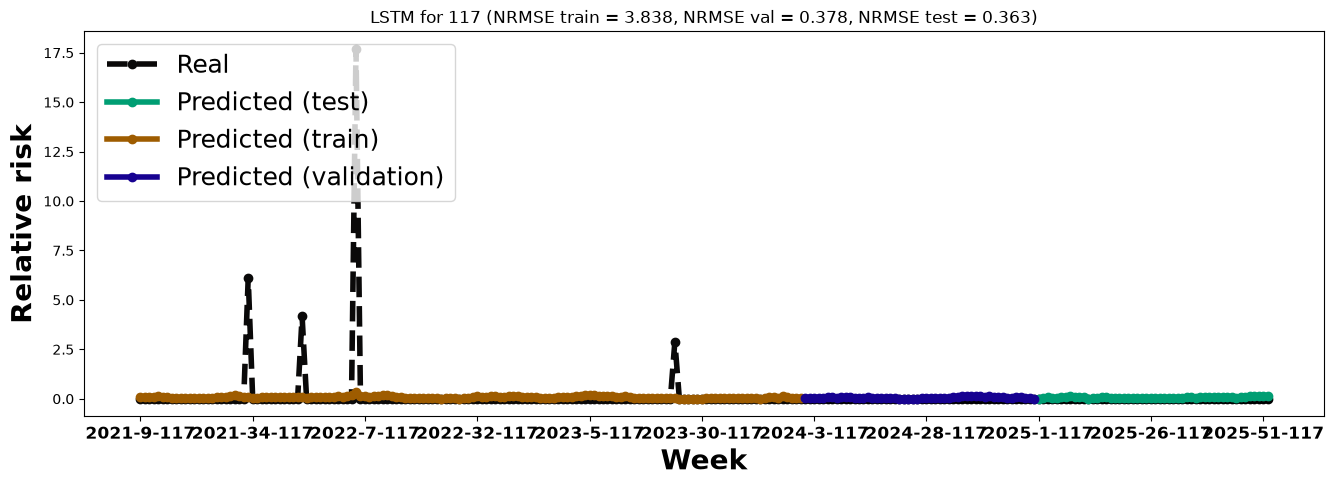

In [7]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()

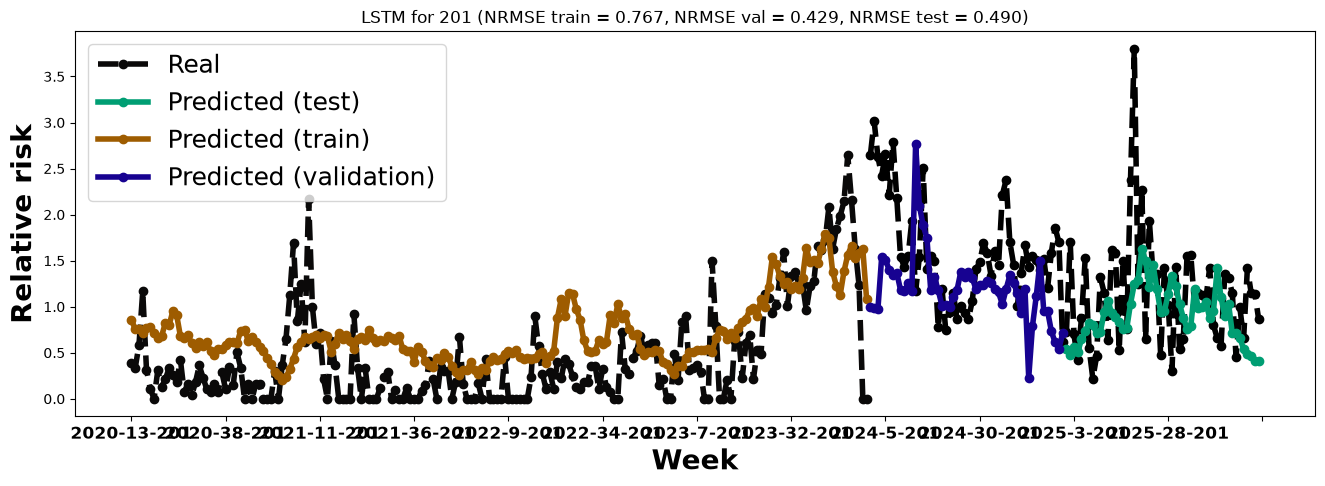

In [8]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()

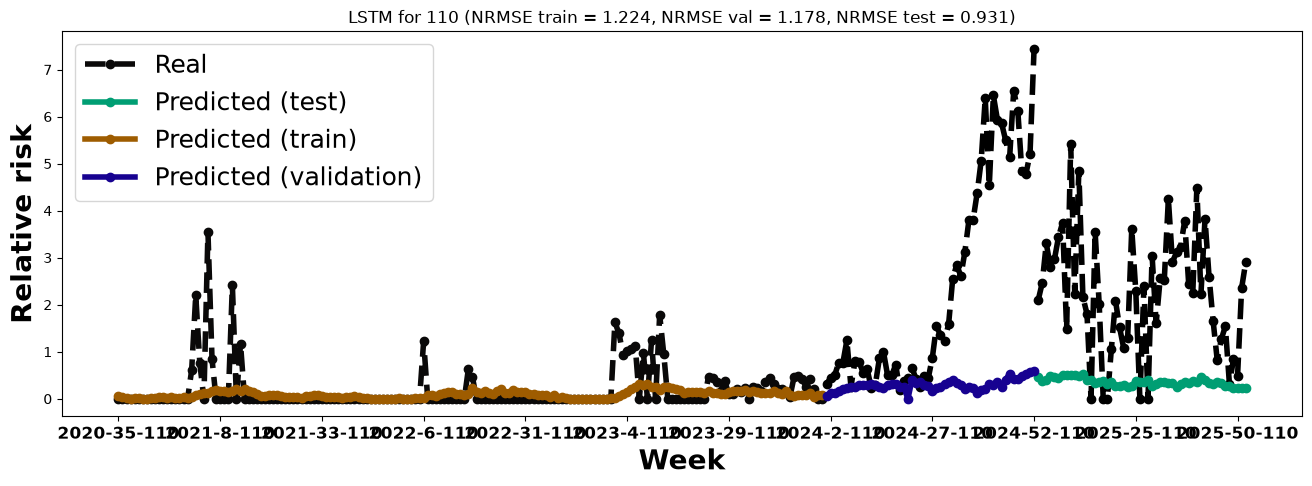

In [9]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()

## Best non-recurrent models

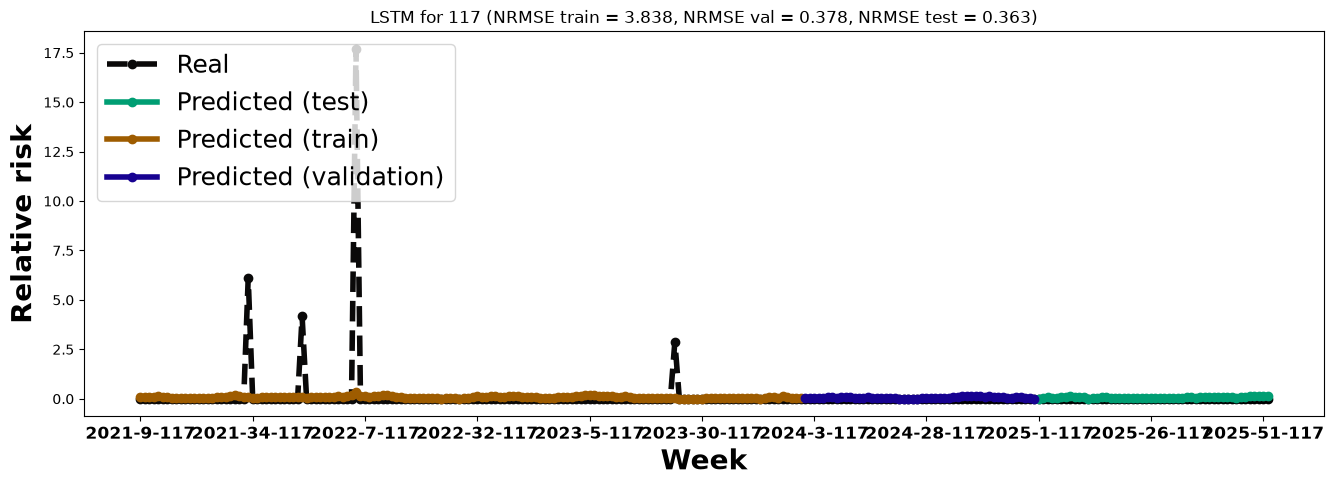

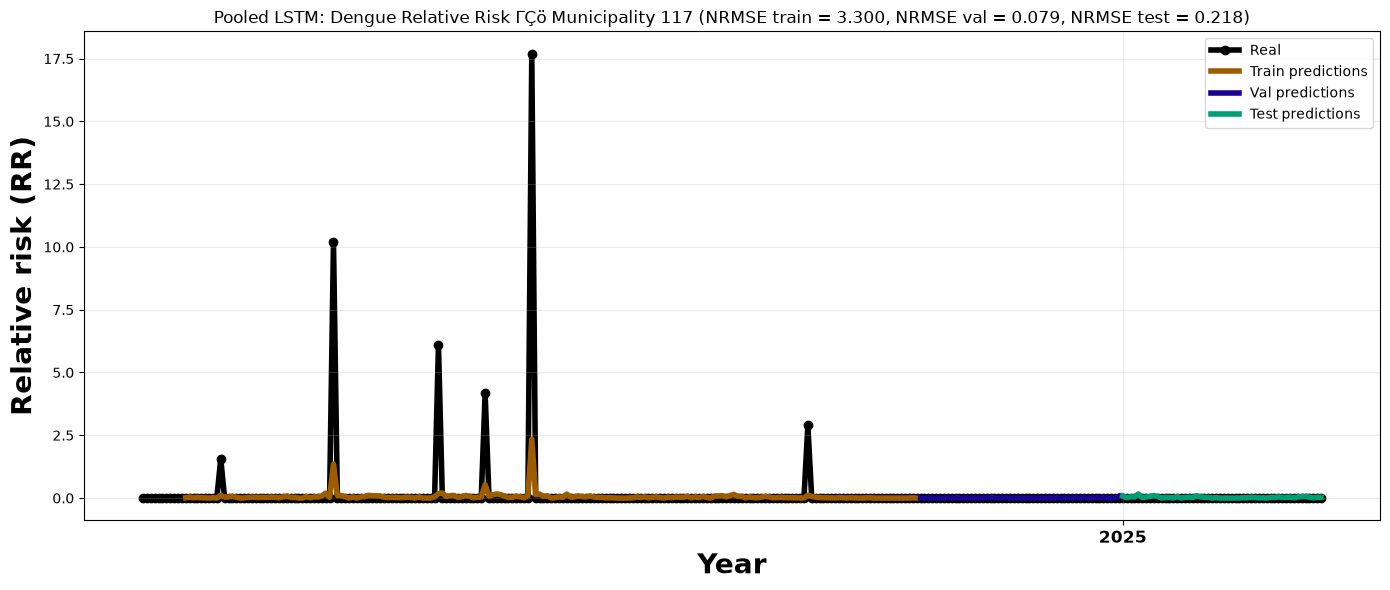

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 117 (NRMSE train = 3.300, NRMSE val = 0.079, NRMSE test = 0.218)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [10]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

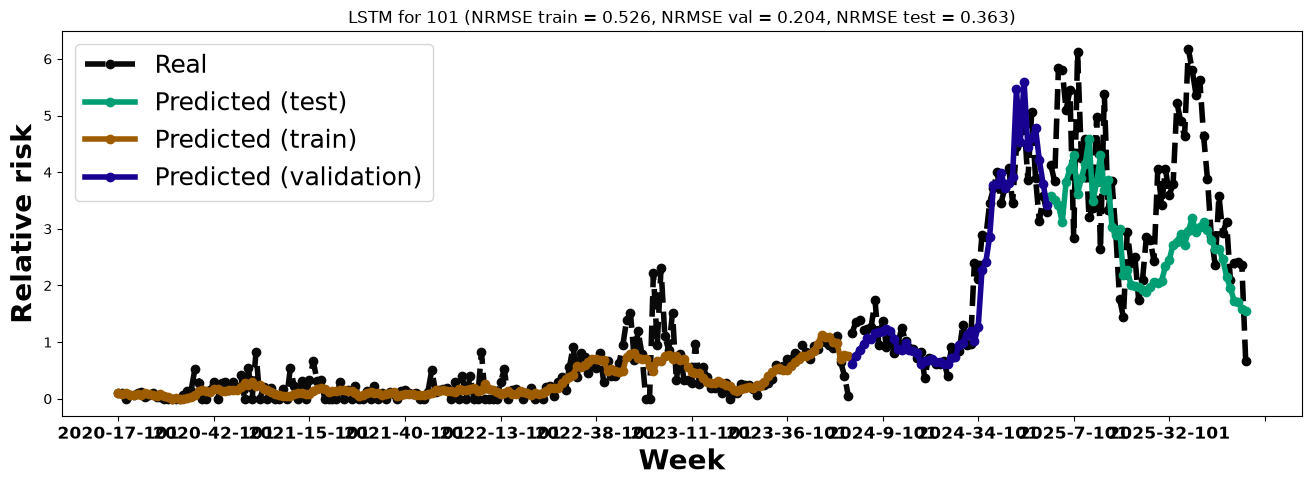

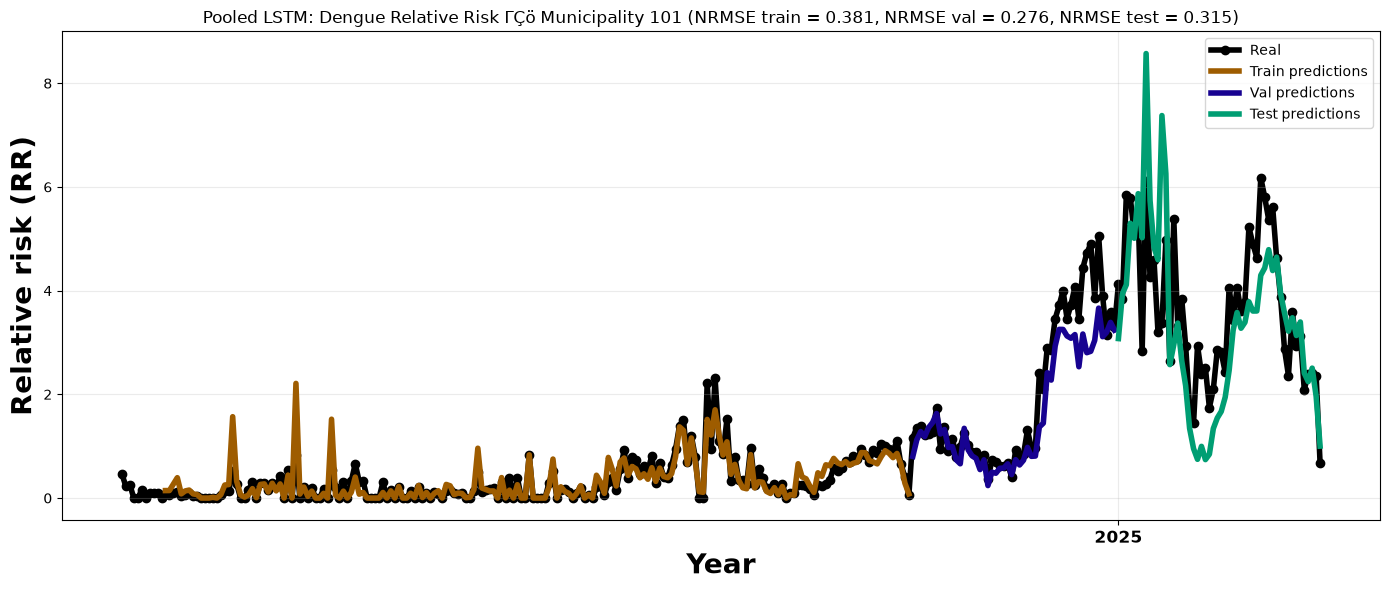

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 101 (NRMSE train = 0.381, NRMSE val = 0.276, NRMSE test = 0.315)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [12]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

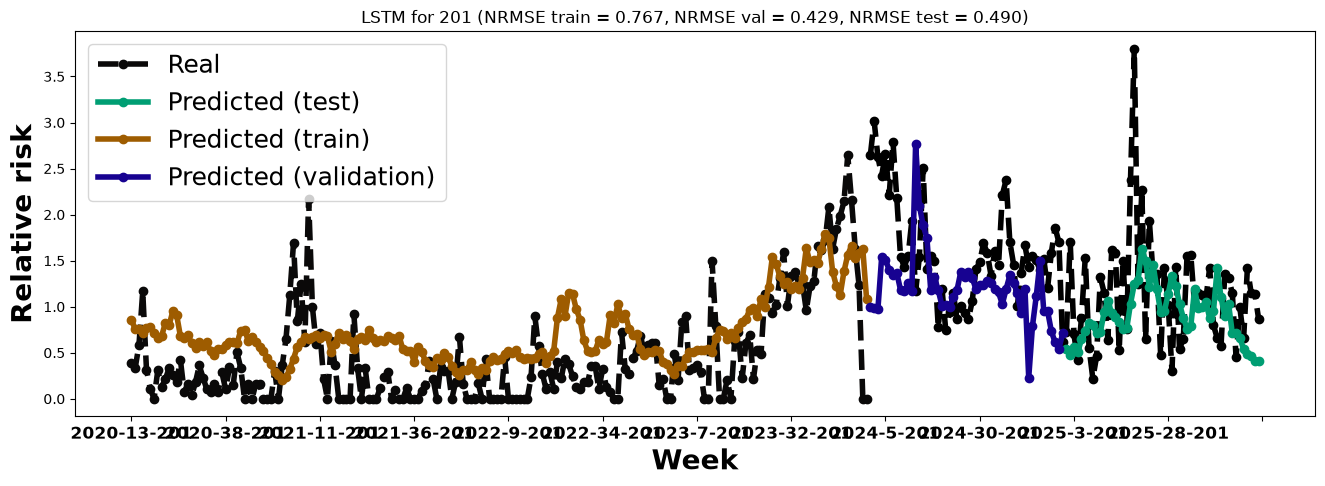

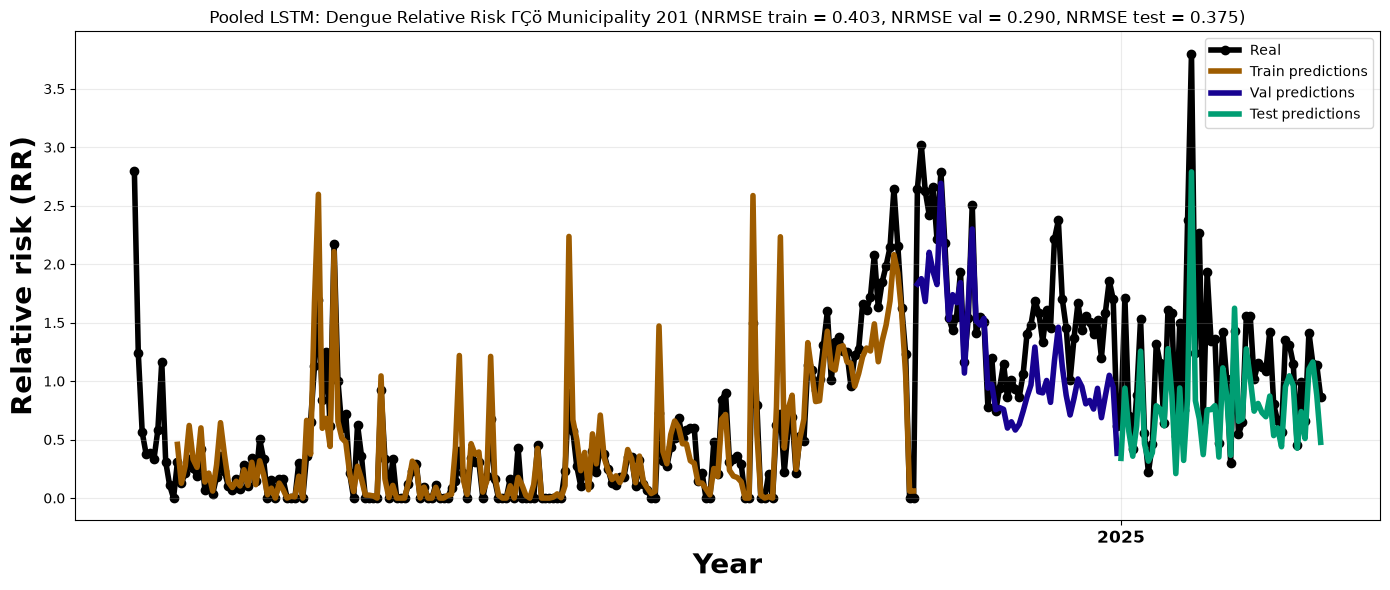

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 201 (NRMSE train = 0.403, NRMSE val = 0.290, NRMSE test = 0.375)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [13]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

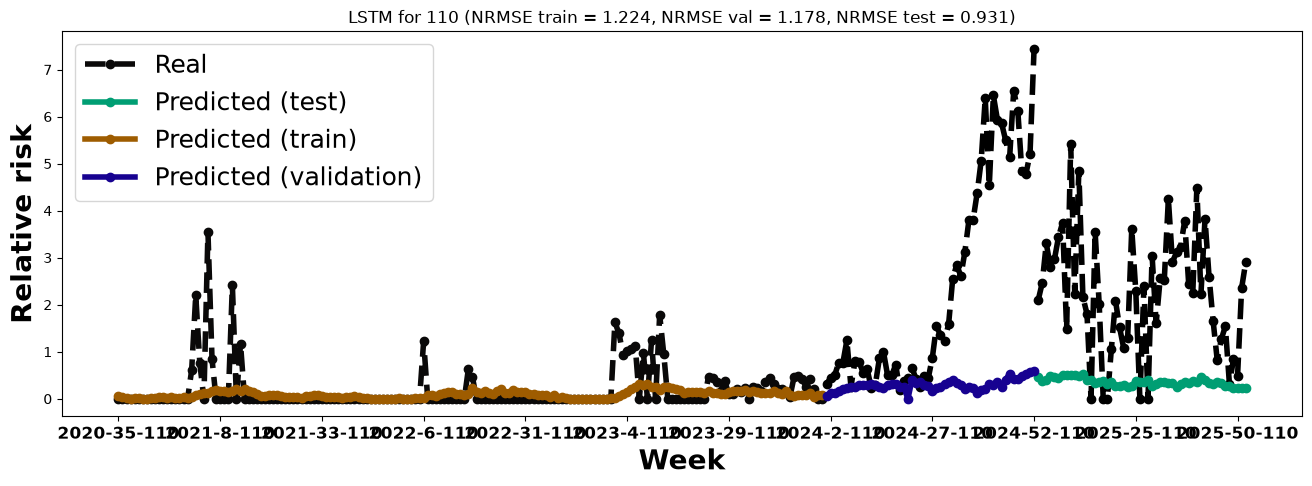

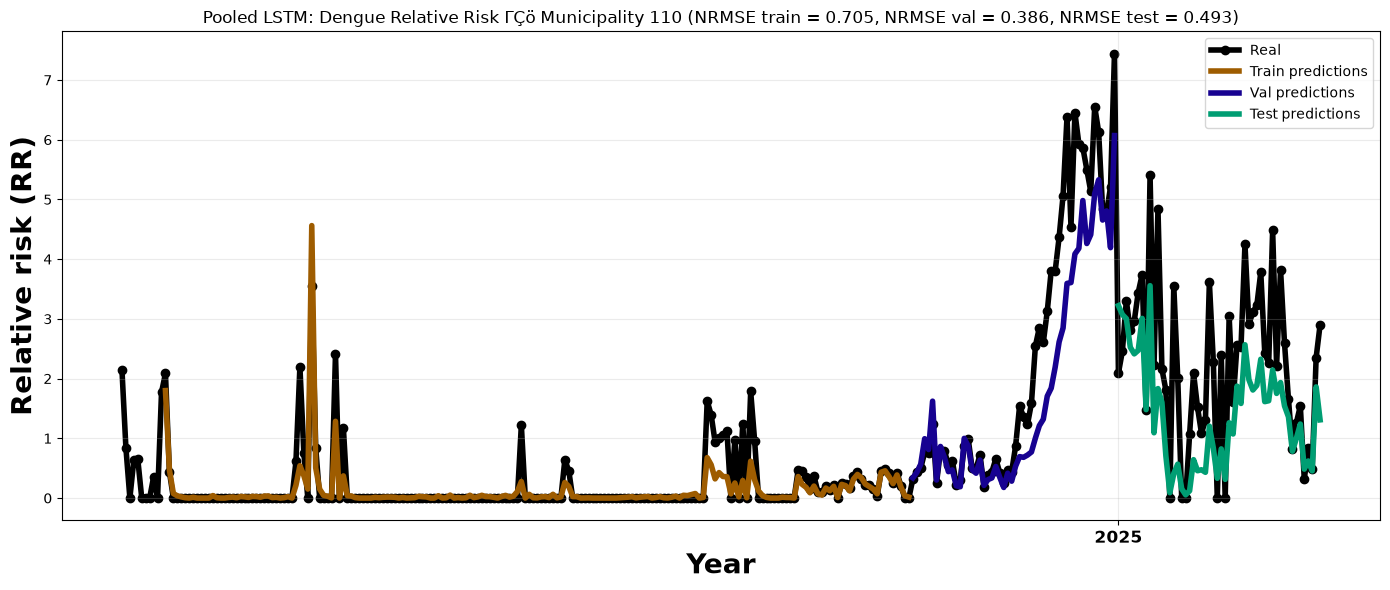

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Pooled LSTM: Dengue Relative Risk ΓÇö Municipality 110 (NRMSE train = 0.705, NRMSE val = 0.386, NRMSE test = 0.493)'}, xlabel='Year', ylabel='Relative risk (RR)'>)

In [14]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

# NRMSE comparison for global and not global models

In [15]:
def plot_nrmse_confint(dataset):

    confints = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )
    
    confint_nofull = confints[["canton", f"{dataset}_point_ind", f"{dataset}_lower_ind",f"{dataset}_upper_ind"]]
    
    confint_nofull["canton"] = confint_nofull["canton"].astype(str)

    confint_full = confints[["canton", f"{dataset}_point_global", f"{dataset}_lower_global",f"{dataset}_upper_global"]]

    confint_full["canton"] = confint_full["canton"].astype(str)

    x = np.arange(len(confint_full))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in confint_nofull.iterrows():
        # Plotting the individual model NRSME results

        mean_col = f"{dataset}_point_ind"
        lower_col = f"{dataset}_lower_ind"
        upper_col = f"{dataset}_upper_ind"
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )
        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in confint_full.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_global"
        lower_col = f"{dataset}_lower_global"
        upper_col = f"{dataset}_upper_global"

        x_full = x[i] + 0.8

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(confint_full["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Individual model", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label="Global model", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 12])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 13, 2), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

C:\Windows\Temp\ipykernel_24596\1138789901.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 13, 2), fontsize = 22, fontweight="bold")


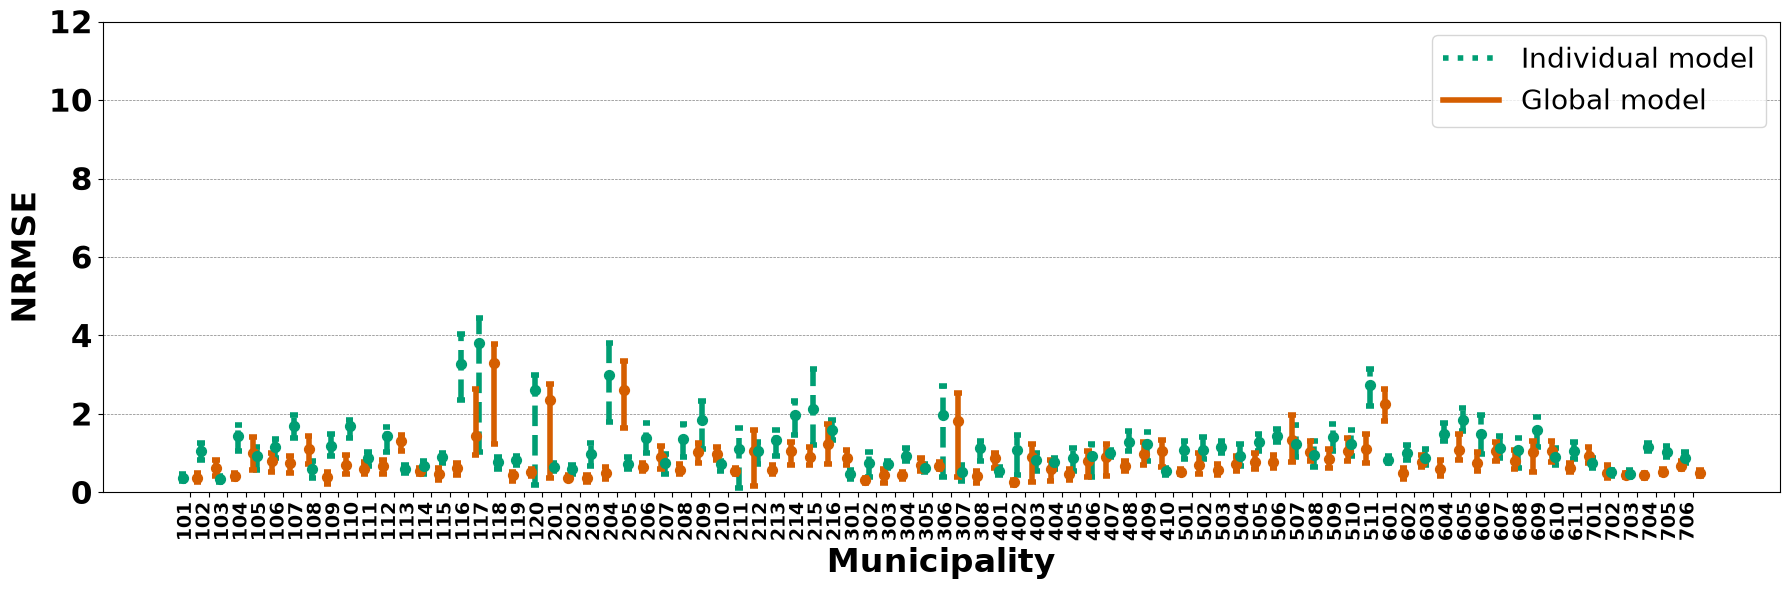

In [ ]:
plot_nrmse_confint("train")

C:\Windows\Temp\ipykernel_24596\1138789901.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 13, 2), fontsize = 22, fontweight="bold")


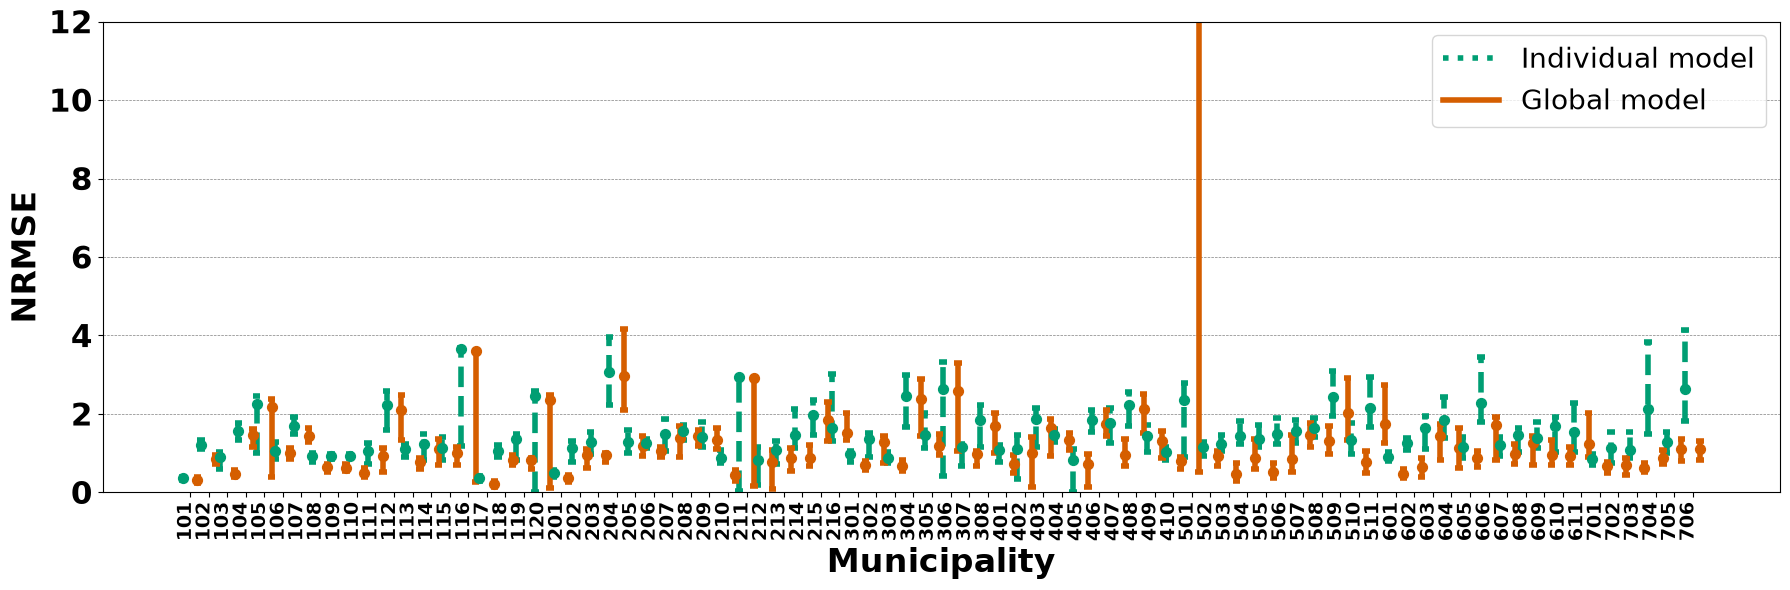

In [ ]:
plot_nrmse_confint("test")